# **intro to linear regression**

In [263]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LinearRegression, Ridge, RidgeCV, LassoCV
from sklearn.model_selection import cross_val_score, GridSearchCV

## **import dataset**

In [264]:
df = pd.read_csv('../data/data.csv')
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [265]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [266]:
df['make'].str.lower().str.replace('-', '_')

0            bmw
1            bmw
2            bmw
3            bmw
4            bmw
          ...   
11909      acura
11910      acura
11911      acura
11912      acura
11913    lincoln
Name: make, Length: 11914, dtype: object

In [267]:
strings = list(df.dtypes[df.dtypes == 'object'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [268]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [269]:

df.dtypes

make                  object
model                 object
year                   int64
engine_fuel_type      object
engine_hp            float64
engine_cylinders     float64
transmission_type     object
driven_wheels         object
number_of_doors      float64
market_category       object
vehicle_size          object
vehicle_style         object
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

#### **shape of data** 

In [270]:
df.shape

(11914, 16)

#### **info of data** 

In [271]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               11914 non-null  object 
 1   model              11914 non-null  object 
 2   year               11914 non-null  int64  
 3   engine_fuel_type   11911 non-null  object 
 4   engine_hp          11845 non-null  float64
 5   engine_cylinders   11884 non-null  float64
 6   transmission_type  11914 non-null  object 
 7   driven_wheels      11914 non-null  object 
 8   number_of_doors    11908 non-null  float64
 9   market_category    8172 non-null   object 
 10  vehicle_size       11914 non-null  object 
 11  vehicle_style      11914 non-null  object 
 12  highway_mpg        11914 non-null  int64  
 13  city_mpg           11914 non-null  int64  
 14  popularity         11914 non-null  int64  
 15  msrp               11914 non-null  int64  
dtypes: float64(3), int64(5

#### **check the number of missing data or null values in the data** 

In [272]:
df.isna().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

#### **descriptive statistics of data** 

In [273]:
df.describe()

,year,engine_hp,engine_cylinders,number_of_doors,highway_mpg,city_mpg,popularity,msrp
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


# **exploratory data analysis**

In [274]:
for col in df.columns:
    print(f"column name: {col}")
    print(f"Number of unique vaues: {df[col].nunique()}")
    print(df[col].unique()[:5])
    print()

column name: make
Number of unique vaues: 48
['bmw' 'audi' 'fiat' 'mercedes-benz' 'chrysler']

column name: model
Number of unique vaues: 914
['1_series_m' '1_series' '100' '124_spider' '190-class']

column name: year
Number of unique vaues: 28
[2011 2012 2013 1992 1993]

column name: engine_fuel_type
Number of unique vaues: 10
['premium_unleaded_(required)' 'regular_unleaded'
 'premium_unleaded_(recommended)' 'flex-fuel_(unleaded/e85)' 'diesel']

column name: engine_hp
Number of unique vaues: 356
[335. 300. 230. 320. 172.]

column name: engine_cylinders
Number of unique vaues: 9
[ 6.  4.  5.  8. 12.]

column name: transmission_type
Number of unique vaues: 5
['manual' 'automatic' 'automated_manual' 'direct_drive' 'unknown']

column name: driven_wheels
Number of unique vaues: 4
['rear_wheel_drive' 'front_wheel_drive' 'all_wheel_drive'
 'four_wheel_drive']

column name: number_of_doors
Number of unique vaues: 3
[ 2.  4.  3. nan]

column name: market_category
Number of unique vaues: 71
['

In [275]:
df

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


# **distribution of msrp(price of vehicles)**

<Axes: xlabel='msrp', ylabel='Count'>

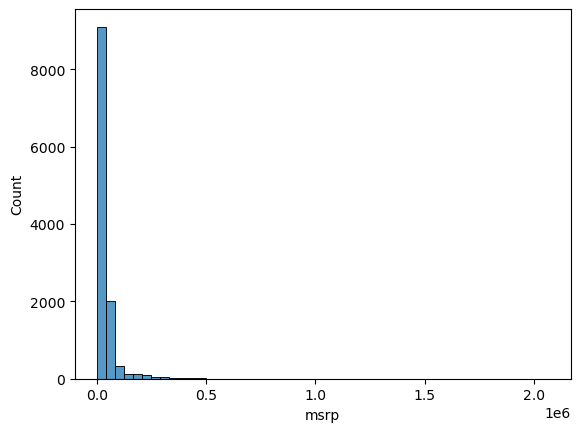

In [276]:
sns.histplot(df["msrp"], bins = 50)

## from histogram, the distribution is a right tail, right skewed
## less expensive cars occupy majority of the distribution
## meaning there are more less expensive cars than more expensive ones

#### **distribution of data with price less than 100000 is still skewed to the right** 
#### **there are more people with less expensive cars than more expensive ones** 

<Axes: xlabel='msrp', ylabel='Count'>

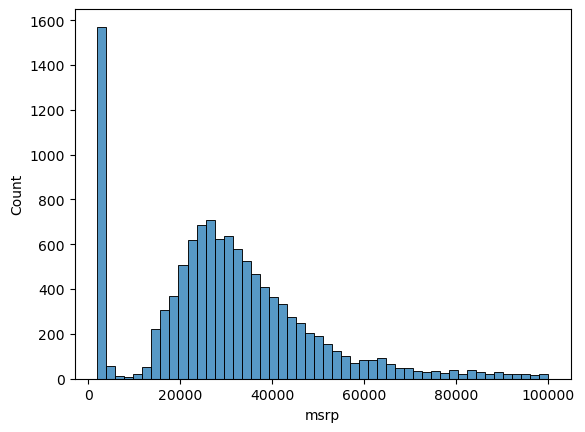

In [277]:
sns.histplot(df["msrp"][df["msrp"] < 100000], bins = 50)

#### **taking log of price, df["msrp"] to scale it down**

<Axes: xlabel='msrp', ylabel='Count'>

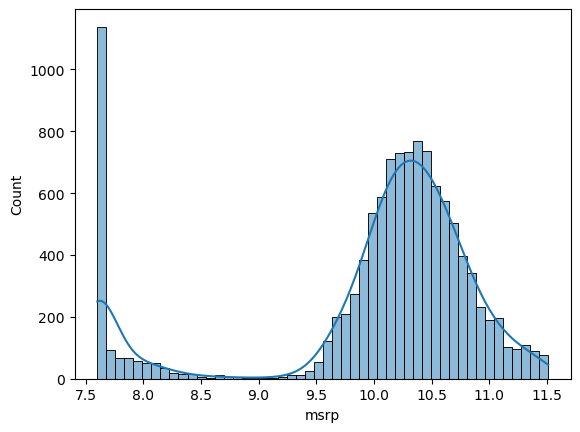

In [278]:
sns.histplot(
    np.log1p(df["msrp"][df["msrp"] < 100000]), 
    bins = 50,
    kde = True,
)


In [279]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

## **setting up validating dataset**

In [280]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='object')

In [281]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [316]:
def linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XT = X.T
    XTX = XT.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(XT.dot(y))
    return w[0], w[1:]

def linear_regression_reg(X, y, r = 0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XT = X.T
    XTX = XT.dot(X)
    XTX = XTX + r*np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(XT.dot(y))
    return w[0], w[1:]

# def prepare_X(df_, column_name, fillna_value):
#     df = df_.copy()

#     df['age'] = 2017 - df.year
#     features = base + ['age']
#     for v in [2, 3, 4]:
#         df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
#         features.append('num_doors_%s' % v)

#     df[column_name] = df[column_name].fillna(fillna_value)
#     df_num = df[features]
#     df_num = df_num.fillna(0)
#     X = df_num.values()
#     return X

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

def split_data(df_, seed):
    n = len(df_)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df_.iloc[idx[:n_train]]
    df_val = df_.iloc[idx[n_train:n_train + n_val]]
    df_test = df_.iloc[idx[n_train+n_val:]]
    
    print(f"df_train shape: {df_train.shape}")
    print(f"df_val shape: {df_val.shape}")
    print(f"df_test shape: {df_test.shape}")

    return df_train, df_val, df_test
    

In [283]:
df_train, df_val, df_test = split_data(df, 2)

df_train shape: (7150, 16)
df_val shape: (2382, 16)
df_test shape: (2382, 16)


In [284]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260


In [285]:

len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

In [286]:

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [287]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [288]:

del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [289]:

len(y_train)

7150

In [240]:
# X_train, X_temp, y_train, y_temp = train_test_split(
#     X, y, 
#     test_size = 0.4,
#     random_state = 24
#     )

# X_test, X_val, y_test, y_val = train_test_split(
#     X_temp, y_temp, 
#     test_size = 0.5,
#     random_state = 24
#     )

# print(df_cp.shape)
# print(f"Train X: {X_train.shape}, Train y: {y_train.shape}" )
# print(f"Temp X: {X_temp.shape}, Temp y: {y_temp.shape}" )
# print(f"Test X: {X_test.shape}, Test y: {y_test.shape}" )
# print(f"Val X: {X_val.shape}, val y: {y_val.shape}" )


## **linear regression**

#### **first we will take out the categrical variables then model it then later we add the categorical variables and model it again**

#### **training model with numeric columns except year and age using X_train**

In [317]:

base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [318]:

base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

X_train = df_train[base].fillna(0).values

w0, w = linear_regression(X_train, y_train)

y_pred = w0 + X_train.dot(w)

In [319]:
w0

np.float64(7.927257388069734)

In [320]:
w

array([ 9.70589522e-03, -1.59103494e-01,  1.43792133e-02,  1.49441072e-02,
       -9.06908672e-06])

<Axes: ylabel='Count'>

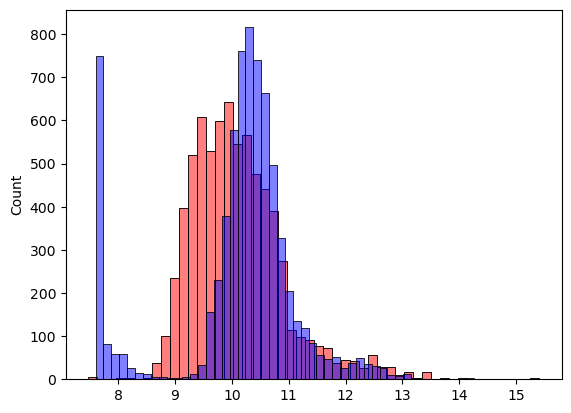

In [321]:

sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [322]:

rmse(y_train, y_pred)

np.float64(0.7554192603920132)

In [323]:
def prepare_x(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [325]:
X_train = prepare_x(df_train)
w0, w = linear_regression(X_train, y_train)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.7616530991301682)

In [326]:
def prepare_x(df):
    df = df.copy()
    
    df['age'] = 2017 - df['year']
    features = base + ['age']
    
    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values

    return X

In [327]:

X_train = prepare_x(df_train)
w0, w = linear_regression(X_train, y_train)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5172055461058405)

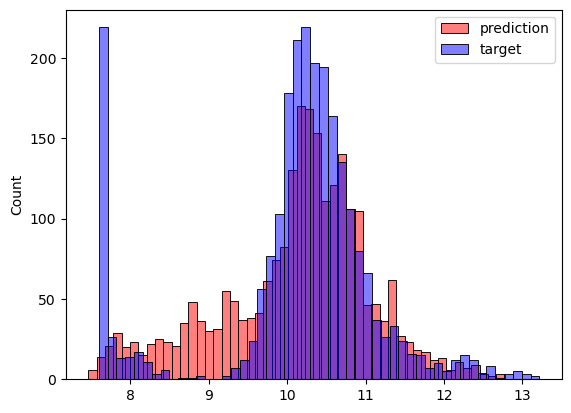

In [328]:

sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue',  alpha=0.5, bins=50)
plt.legend()


## **metrics**

In [329]:
rmse(y_val, y_pred)

np.float64(0.5172055461058405)

## **handling categorical variables**

In [330]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [331]:
df["number_of_doors"].unique()

array([ 2.,  4.,  3., nan])

In [332]:
(df_train["number_of_doors"] == 2).astype("int")

0       1
1       0
2       0
3       0
4       0
       ..
7145    1
7146    1
7147    0
7148    0
7149    0
Name: number_of_doors, Length: 7150, dtype: int64

In [334]:
def prepare_x(df):
    df = df.copy()
    
    df['age'] = 2017 - df['year']
    features = base + ['age']

    for v in [2, 3, 4]:
        df['num_doors_%d' % v] = (df.number_of_doors == v).astype(int)
        features.append('num_doors_%d' % v)

    # for name, values in categorical.items():
    #     for value in values:
    #         df['%s_%s' % (name, value)] = (df[name] == value).astype(int)
    #         features.append('%s_%s' % (name, value))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values

    return X

In [335]:

X_train = prepare_x(df_train)
w0, w = linear_regression(X_train, y_train)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.515799564150248)

In [336]:
makes = list(df.make.value_counts().head().index)

In [337]:
def prepare_x(df):
    df = df.copy()
    features = base.copy()
    
    df['age'] = 2017 - df['year']
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%d' % v] = (df.number_of_doors == v).astype(int)
        features.append('num_doors_%d' % v)

    for v in makes:
        df['make_%s' % v] = (df.make == v).astype(int)
        features.append('make_%s' % v)

    # for name, values in categorical.items():
    #     for value in values:
    #         df['%s_%s' % (name, value)] = (df[name] == value).astype(int)
    #         features.append('%s_%s' % (name, value))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values

    return X

In [338]:

X_train = prepare_x(df_train)
w0, w = linear_regression(X_train, y_train)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5076038849557367)

In [339]:
categorical_variables = [
    'make', 'model', 'engine_fuel_type', 'driven_wheels', 'market_category',
    'vehicle_size', 'vehicle_style']

categorical = {}

for c in categorical_variables:
    categorical[c] = list(df_train[c].value_counts().head().index)

In [ ]:
categorical

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'model': ['silverado_1500', 'tundra', 'f-150', 'sierra_1500', 'tacoma'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'hatchback',
  'luxury,performance'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [345]:
def prepare_x(df):
    df = df.copy()
    # features = base.copy()
    
    df['age'] = 2017 - df['year']
    features = base + ['age']

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype(int)
        features.append('num_doors_%s' % v)

    # for v in makes:
    #     df['make_%s' % v] = (df.make == v).astype(int)
    #     features.append('make_%s' % v)

    for name, values in categorical.items():
        for value in values:
            df['%s_%s' % (name, value)] = (df[name] == value).astype(int)
            features.append('%s_%s' % (name, value))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values

    return X

In [346]:

X_train = prepare_x(df_train)
w0, w = linear_regression(X_train, y_train)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(69.69120432544337)

## **Regularization**

In [349]:
w0, w

(np.float64(3279344024170320.0),
 array([ 1.27149048e-02, -1.09536668e+01, -3.22416568e+00, -1.07894094e+00,
        -4.09648797e-04, -1.32422063e+00, -2.68331703e+03, -2.69651348e+03,
        -2.68187635e+03,  1.44339909e+00, -3.22204283e+00,  1.10749868e+00,
         5.14381481e+00, -5.28227175e-01,  1.11094990e+00, -1.22136903e+01,
        -3.33041712e+00,  6.74060875e+00, -1.76266779e+01,  4.71651935e+01,
         4.63337211e+01,  4.96916265e+01,  5.68556476e+01,  1.78386159e+01,
        -3.27934402e+15, -3.27934402e+15, -3.27934402e+15, -3.27934402e+15,
        -3.48903886e-01, -1.78735847e-01,  5.98717913e+00,  1.52437823e+01,
         8.36433555e+00,  2.80000000e+01,  9.00000000e+00,  1.50000000e+01,
        -1.44115660e-01, -2.62579827e-02,  1.75913981e-01,  3.65037816e-01,
        -2.90235596e-01]))

In [351]:
X_train = prepare_x(df_train)
w0, w = linear_regression_reg(X_train, y_train, r = 0.1)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.4608736549080242)

## **Tuning the model**

In [353]:

for r in [0.0, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]:
    X_train = prepare_x(df_train)
    w0, w = linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_x(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    
    print(r, w0, score)

0.0 3279344024170320.0 69.69120432544337
1e-05 5.7961366176605225 0.4608153025223411
0.0001 7.133213818073273 0.46081536321842775
0.001 7.130980528891087 0.46081585836049843
0.01 7.118381644366309 0.46082082860375906
0.1 7.00023242647876 0.4608736549080242
1 6.250747848011088 0.461581283826909
10 4.729512585675366 0.47260987726686976


In [354]:
r = 0.001
X_train = prepare_x(df_train)
w0, w = linear_regression_reg(X_train, y_train, r = r)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.46081585836049843)

## **Using the model**

In [355]:
df_train_full = pd.concat([df_train, df_val], ignore_index=True)
df_train_full

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9527,volvo,v60,2015,regular_unleaded,240.0,4.0,automatic,front_wheel_drive,4.0,luxury,midsize,wagon,37,25,870
9528,maserati,granturismo_convertible,2015,premium_unleaded_(required),444.0,8.0,automatic,rear_wheel_drive,2.0,"exotic,luxury,high-performance",midsize,convertible,20,13,238
9529,cadillac,escalade_hybrid,2013,regular_unleaded,332.0,8.0,automatic,rear_wheel_drive,4.0,"luxury,hybrid",large,4dr_suv,23,20,1624
9530,mitsubishi,lancer,2016,regular_unleaded,148.0,4.0,manual,front_wheel_drive,4.0,NaN,compact,sedan,34,24,436


In [357]:
X_full_train = prepare_x(df_train_full)
X_full_train

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [332.,   8.,  23., ...,   0.,   0.,   0.],
       [148.,   4.,  34., ...,   0.,   0.,   0.],
       [290.,   6.,  25., ...,   0.,   0.,   0.]], shape=(9532, 41))

In [358]:
y_full_train = np.concatenate([y_train, y_val])

In [359]:
w0, w = linear_regression_reg(X_full_train, y_full_train, r = 0.001)


In [361]:
w0, w

(np.float64(7.175353981554508),
 array([ 1.80193321e-03,  1.26575147e-01, -6.78607932e-03,  7.75903898e-03,
        -5.33226049e-05, -9.73063836e-02, -1.27241612e+00, -1.30599181e+00,
        -9.95969459e-01, -6.27479230e-02,  1.82139251e-01,  2.83073929e-02,
         1.29063848e-02, -1.32624474e-01, -2.69110367e-01, -6.50985203e-01,
        -3.21721814e-01, -3.55424920e-01, -3.51216065e-01, -6.61059062e-01,
        -1.19526958e-01, -5.15904861e-01, -6.99730903e-01, -3.25276703e-01,
         1.80630972e+00,  1.75062342e+00,  1.82819593e+00,  1.79006439e+00,
        -5.47616398e-02,  1.19033258e-01, -2.65289021e-02,  7.42028657e-03,
        -7.49067100e-03,  2.42691845e+00,  2.35931690e+00,  2.38908612e+00,
        -1.47584145e-01, -2.46551739e-02,  1.81542645e-01,  3.55084073e-01,
        -2.79089708e-01]))

In [363]:
X_test = prepare_x(df_test)
y_pred = w0 + X_test.dot(w)
rmse(y_test, y_pred)

np.float64(0.46007539647934437)

In [365]:
car = df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

In [367]:
df_small = pd.DataFrame([car])
df_small

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,toyota,sienna,2015,regular_unleaded,266.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,25,18,2031


In [369]:
X_small = prepare_x(df_small)
y_pred = w0 + X_small.dot(w)
y_pred = np.expm1(y_pred)
y_pred

array([41459.33839358])

In [371]:
np.expm1(y_test[20])

np.float64(35000.00000000001)